# De la señal a la pseudodistancia: qué mide un receptor GNSS

Este cuaderno acompaña la unidad de *sistemas de posicionamiento satelital (GNSS)*. Parte de un día de datos reales —la estación permanente **BOGT** (Bogotá, red IGS, operada por NASA/JPL), 15 de septiembre de 2026— y separa, término a término, la **ecuación de la pseudodistancia**, el punto de partida de todo el posicionamiento por satélite.

Cada sección sigue el mismo patrón: una definición, las ecuaciones paso a paso, el cálculo con los datos y, cuando ayuda, una figura con su lectura. Los datos son los dos archivos RINEX del día, guardados en `data/`; la **sección 0** los lee y arma la tabla con la que trabaja el resto del cuaderno. Las cifras que aparecen en el texto son las de BOGT el 15 de septiembre a las 12:00:00 con el satélite G15; con otra estación, otra fecha u otro satélite los cálculos se repiten igual y los números cambian.

**La tabla `D`** tiene una fila por época y satélite GPS:

| columna | qué es | unidad |
|---|---|---|
| `t` | instante de la medida (época), en tiempo GPS | fecha y hora |
| `sv` | satélite (G + número PRN) | — |
| `P1`, `P2` | **pseudodistancia** ($P$ en las ecuaciones; en la literatura suele escribirse $\rho$): la distancia que mide el receptor a partir del tiempo de viaje de la señal, con el código C/A en L1 (`C1C`) y con el código en L2 (`C2W` u otro disponible); incluye el efecto de los relojes y de la atmósfera | m |
| `L1` | fase de la portadora L1 (conteo de ciclos) | ciclos |
| `S1` | intensidad de la señal recibida en L1 | dB·Hz |
| `xs`, `ys`, `zs` | posición del satélite en el instante en que emitió la señal, calculada con sus efemérides | m (geocéntricas) |
| `dts` | desfase del reloj del satélite, $\delta t^s$, calculado con los coeficientes que él mismo transmite y descontando su retardo de grupo $T_{GD}$ (sección 0) | s |
| `el`, `az` | elevación y acimut del satélite vistos desde la estación | grados |
| `r` | **distancia geométrica**: la distancia real, en línea recta, entre el satélite (en el instante de emisión) y la estación, calculada con sus dos posiciones; se agrega en la sección 7 | m |
| `resid` | **residuo de pseudodistancia** $P1 - r + c\,\delta t^s$, igual a $c\,\delta t_R + T + I + \varepsilon$; se agrega en la sección 7 | m |

> **Estación GNSS permanente** — receptor con antena fija que registra sin interrupción las señales de los satélites de navegación y publica sus datos. BOGT pertenece al **IGS** (*International GNSS Service*), la red mundial de estaciones de este tipo que existe desde 1994.

### Datos de otras estaciones

Los archivos del IGS se descargan sin registro del centro de datos de BKG (Alemania). La ruta es `https://igs.bkg.bund.de/root_ftp/IGS/obs/AAAA/DDD/`, con el año y el **día del año** (el 15 de septiembre de 2026 es el día 258), y el nombre de cada archivo se arma así:

`BOGT00COL_R_20262580000_01D_30S_MO.crx.gz` = estación `BOGT`, monumento y receptor `00`, país `COL` · `R` datos del receptor · `2026258` año y día · `0000` hora de inicio · `01D` un día · `30S` una época cada 30 s · `MO` observaciones (`MN` navegación) · `.crx.gz` comprimido (Hatanaka + gzip).

Enlaces comprobados el 23-oct-2026 para el **15 de septiembre de 2026** (para otro día se cambian `2026/258` y `2026258`):

| estación | lugar | observación | navegación | ficha IGS |
|---|---|---|---|---|
| `BOGT00COL` | Bogotá, Colombia | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/BOGT00COL_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/BOGT00COL_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/BOGT00COL) |
| `GLPS00ECU` | Puerto Ayora, Galápagos, Ecuador | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/GLPS00ECU_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/GLPS00ECU_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/GLPS00ECU) |
| `AREQ00PER` | Arequipa, Perú | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/AREQ00PER_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/AREQ00PER_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/AREQ00PER) |
| `SANT00CHL` | Santiago, Chile | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/SANT00CHL_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/SANT00CHL_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/SANT00CHL) |
| `KOUR00GUF` | Kourou, Guayana Francesa | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/KOUR00GUF_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/KOUR00GUF_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/KOUR00GUF) |
| `CHPI00BRA` | Cachoeira Paulista, Brasil | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/CHPI00BRA_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/CHPI00BRA_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/CHPI00BRA) |
| `CRO100VIR` | Saint Croix, Islas Vírgenes (EE. UU.) | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/CRO100VIR_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/CRO100VIR_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/CRO100VIR) |
| `LMMF00MTQ` | Le Lamentin, Martinica | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/LMMF00MTQ_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/LMMF00MTQ_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/LMMF00MTQ) |
| `ALGO00CAN` | Algonquin Park, Canadá | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/ALGO00CAN_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/ALGO00CAN_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/ALGO00CAN) |
| `WTZR00DEU` | Wettzell, Alemania | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/WTZR00DEU_R_20262580000_01D_30S_MO.crx.gz) | [navegación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/WTZR00DEU_R_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/WTZR00DEU) |

Estas estaciones publican la observación pero no su propio archivo de navegación; se usa el archivo de navegación combinado de toda la red, que el cuaderno toma solo si falta el de la estación:

| estación | lugar | observación | navegación | ficha IGS |
|---|---|---|---|---|
| `BRAZ00BRA` | Brasilia, Brasil | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/BRAZ00BRA_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/BRAZ00BRA) |
| `UNSA00ARG` | Salta, Argentina | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/UNSA00ARG_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/UNSA00ARG) |
| `LPGS00ARG` | La Plata, Argentina | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/LPGS00ARG_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/LPGS00ARG) |
| `INEG00MEX` | Aguascalientes, México | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/INEG00MEX_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/INEG00MEX) |
| `UFPR00BRA` | Curitiba, Brasil | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/UFPR00BRA_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/UFPR00BRA) |
| `BELE00BRA` | Belém, Brasil | [observación](https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/BELE00BRA_R_20262580000_01D_30S_MO.crx.gz) | [navegación combinada](https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/BRDC00WRD_S_20262580000_01D_MN.rnx.gz) | [ficha](https://network.igs.org/BELE00BRA) |

Para buscar más:

- Mapa de estaciones del IGS, con la ficha de cada una (receptor, antena, coordenadas, fotos): https://network.igs.org/
- Buscador de archivos de BKG: https://igs.bkg.bund.de/searchRINEX
- Listado completo de un día: https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/ y la navegación combinada en https://igs.bkg.bund.de/root_ftp/IGS/BRDC/2026/258/
- Estaciones de la Red Geodésica Nacional de Colombia (IGAC), en Colombia en Mapas: https://www.colombiaenmapas.gov.co/ (pueden venir en RINEX 2; este cuaderno lee RINEX 3).
- Archivo CDDIS de la NASA (mismos datos, requiere cuenta gratuita de Earthdata): https://cddis.nasa.gov/archive/gnss/data/daily/

Para procesar otra estación: cambiar `ESTACION`, `FECHA`, `HORA`, `SAT` y `HUSO` en la primera celda de la sección 0 y poner `DESCARGAR = True` (o dejar los dos archivos en `data/`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
AZUL, ROJO, VERDE, GRIS, NARANJA = "#1F3864", "#9C0006", "#375623", "#7F7F7F", "#C55A11"

# velocidad de la luz en el vacío (m/s): valor exacto, porque define el metro en el SI
C = 299792458.0

## 0. Lectura de los archivos RINEX y tabla de observaciones

> **RINEX** (*Receiver Independent Exchange Format*) — formato de texto estándar en el que cualquier receptor publica sus medidas. Hay dos archivos por día y estación: el de **observación** (`…_MO`), con una línea por época y satélite, y el de **navegación** (`…_MN`), con las efemérides y la corrección del reloj que transmitió cada satélite.

Esta sección lee los dos archivos de la estación y arma una tabla `D` con una fila por época y satélite GPS. Para usar otra estación u otro día basta cambiar `ESTACION` y `FECHA` en la celda siguiente, y si hace falta la época (`HORA`), el satélite que se sigue (`SAT`) y el huso horario (`HUSO`) (con `DESCARGAR = True` el cuaderno baja los archivos del centro de datos del IGS en BKG si no están en `data/`). Requiere el paquete `hatanaka` (`pip install hatanaka`), que descomprime el formato comprimido de los archivos de observación (`.crx`).

In [2]:
# ── qué estación y qué día se procesan ──
ESTACION = "BOGT00COL"      # nombre IGS de 9 caracteres: 4 letras de la estación, monumento y receptor (00) y país (COL)
FECHA = "2026-09-15"        # día de los archivos (UTC)
HORA = "12:00:00"           # la época que se estudia en detalle (tiempo GPS)
SAT = "G15"                 # el satélite que se sigue durante su pase (debe estar visible a esa HORA)
HUSO = -5                   # hora local = UTC + HUSO (Colombia: −5)
DESCARGAR = False           # True: baja de BKG los archivos que no estén en data/

import gzip, urllib.request
from pathlib import Path
import hatanaka

dia = pd.Timestamp(FECHA)
ANIO, DDD = dia.year, f"{dia.dayofyear:03d}"            # el día del año: 15-sep-2026 es el 258
BKG = "https://igs.bkg.bund.de/root_ftp/IGS"
f_obs = f"{ESTACION}_R_{ANIO}{DDD}0000_01D_30S_MO.crx.gz"     # observaciones, una época cada 30 s
f_nav = f"{ESTACION}_R_{ANIO}{DDD}0000_01D_MN.rnx.gz"         # navegación grabada por la propia estación
f_brdc = f"BRDC00WRD_S_{ANIO}{DDD}0000_01D_MN.rnx.gz"         # navegación combinada de toda la red (si la estación no publica la suya)
DATA = Path("data")

def conseguir(nombre, url):
    """Devuelve la ruta local del archivo; si no está y DESCARGAR es True, lo baja. None si no existe en ninguna parte."""
    ruta = DATA / nombre
    if not ruta.exists() and DESCARGAR:
        try:
            urllib.request.urlretrieve(url, ruta)
            print("descargado:", nombre)
        except Exception as error:
            print("no disponible:", url, "|", error)
            return None
    return ruta if ruta.exists() else None

ruta_obs = conseguir(f_obs, f"{BKG}/obs/{ANIO}/{DDD}/{f_obs}")
ruta_nav = conseguir(f_nav, f"{BKG}/obs/{ANIO}/{DDD}/{f_nav}") or conseguir(f_brdc, f"{BKG}/BRDC/{ANIO}/{DDD}/{f_brdc}")
assert ruta_obs is not None and ruta_nav is not None, "faltan archivos: póngalos en data/ o use DESCARGAR = True"

# .crx.gz -> .rnx (Hatanaka + gzip) y .rnx.gz -> .rnx; si ya estaban descomprimidos no se repite
rnx_obs = hatanaka.decompress_on_disk(ruta_obs)
rnx_nav = hatanaka.decompress_on_disk(ruta_nav)
print("observación:", rnx_obs.name, "\nnavegación: ", rnx_nav.name)

observación: BOGT00COL_R_20262580000_01D_30S_MO.rnx 
navegación:  BOGT00COL_R_20262580000_01D_MN.rnx


In [3]:
def leer_obs_gps(ruta):
    """Lee un RINEX 3 de observación. Devuelve el encabezado (dict) y una tabla con una fila por época y satélite GPS."""
    lineas = open(ruta, encoding="latin-1").read().splitlines()
    enc, tipos, i = {}, {}, 0
    while True:                                               # encabezado: la etiqueta está en las columnas 61-80
        l, etiqueta = lineas[i], lineas[i][60:].strip()
        if etiqueta == "END OF HEADER":
            i += 1
            break
        if etiqueta == "SYS / # / OBS TYPES":
            if l[0] != " ":
                sistema = l[0]
                tipos[sistema] = l[7:60].split()
            else:                                             # línea de continuación (más de 13 tipos)
                tipos[sistema] += l[7:60].split()
        elif etiqueta == "APPROX POSITION XYZ":
            enc["xyz"] = [float(v) for v in l[:60].split()]
        elif etiqueta == "MARKER NAME":
            enc["estacion"] = l[:60].strip()
        elif etiqueta == "REC # / TYPE / VERS":
            enc["receptor"] = l[20:40].strip()
        elif etiqueta == "ANT # / TYPE":
            enc["antena"] = l[20:40].strip()
        elif etiqueta == "ANTENNA: DELTA H/E/N":
            enc["antena_dh"] = float(l[:14])                  # altura de la antena sobre el marcador (m)
        elif etiqueta == "INTERVAL":
            enc["intervalo_s"] = float(l[:60])
        i += 1
    tg = tipos["G"]                                           # los tipos de observación de GPS, en su orden
    filas = []
    while i < len(lineas):
        l = lineas[i]
        if l.startswith(">"):                                 # línea de época: > aaaa mm dd hh mm ss.sssssss bandera n
            t = pd.Timestamp(int(l[2:6]), int(l[7:9]), int(l[10:12]), int(l[13:15]), int(l[16:18])) + pd.Timedelta(seconds=float(l[19:29]))
            n = int(l[32:35])
            for ll in lineas[i + 1:i + 1 + n]:
                if ll[0] == "G":                              # solo GPS; cada valor ocupa 16 columnas (14 del número + 2 banderas)
                    valores = [ll[3 + 16 * j:3 + 16 * j + 14].strip() for j in range(len(tg))]
                    filas.append([t, ll[:3]] + [float(v) if v else np.nan for v in valores])
            i += 1 + n
        else:
            i += 1
    enc["tipos_gps"] = tg
    return enc, pd.DataFrame(filas, columns=["t", "sv"] + tg)

enc, obs = leer_obs_gps(rnx_obs)
rx = np.array(enc["xyz"])          # posición de la estación del encabezado (APPROX POSITION XYZ): aproximada, al metro o mejor

# el código en L2 varía según el receptor: se usa el primero que tenga datos
codigo_L2 = next((c for c in ["C2W", "C2L", "C2X", "C2S", "C2P", "C2D"] if c in obs and obs[c].notna().any()), None)
obs["P2"] = obs[codigo_L2] if codigo_L2 else np.nan
for col in ["L1C", "S1C"]:                 # no todos los receptores registran la fase o la intensidad de L1C
    if col not in obs:
        obs[col] = np.nan
print(f"{enc['estacion']} · receptor {enc['receptor']} · antena {enc['antena']} · intervalo {enc['intervalo_s']:.0f} s")
print("tipos de observación GPS:", " ".join(enc["tipos_gps"]))
print("código usado en L2:", codigo_L2, "| filas GPS:", len(obs), "| épocas:", obs.t.nunique())

BOGT · receptor JAVAD TRE_3 DELTA · antena JAVRINGANT_DM   NONE · intervalo 30 s
tipos de observación GPS: C1C L1C S1C C1W L1W S1W C2X L2X S2X C2W L2W S2W C5X L5X S5X C1X L1X S1X
código usado en L2: C2W | filas GPS: 27358 | épocas: 2880


In [4]:
def leer_nav_gps(ruta):
    """Lee un RINEX 3 de navegación y devuelve las efemérides GPS: una fila por mensaje, con el instante de referencia del reloj (toc)."""
    lineas = open(ruta, encoding="latin-1").read().splitlines()
    i = next(k for k, l in enumerate(lineas) if "END OF HEADER" in l) + 1
    num = lambda s: float(s.replace("D", "E")) if s.strip() else np.nan        # los números vienen en notación Fortran (1.2D-03)
    campos = ["IODE", "Crs", "DeltaN", "M0", "Cuc", "e", "Cus", "sqrtA", "Toe", "Cic", "Omega0", "Cis",
              "i0", "Crc", "omega", "OmegaDot", "IDOT", "L2codes", "semana", "L2P", "precision", "salud", "TGD", "IODC"]
    lineas_por_sistema = {"G": 8, "E": 8, "C": 8, "J": 8, "I": 8, "R": 4, "S": 4}   # cada mensaje ocupa 8 líneas (GLONASS y SBAS, 4)
    filas = []
    while i < len(lineas):
        l = lineas[i]
        n = lineas_por_sistema.get(l[0], 1)
        if l[0] == "G":
            toc = pd.Timestamp(int(l[4:8]), int(l[9:11]), int(l[12:14]), int(l[15:17]), int(l[18:20]), int(l[21:23]))
            reloj = [num(l[23 + 19 * k:42 + 19 * k]) for k in range(3)]                  # af0 (s), af1 (s/s), af2 (s/s²)
            resto = [num(ll[4 + 19 * k:23 + 19 * k]) for ll in lineas[i + 1:i + 7] for k in range(4)]
            filas.append([l[:3], toc] + reloj + resto)
        i += n
    nav = pd.DataFrame(filas, columns=["sv", "toc", "af0", "af1", "af2"] + campos)
    return nav[nav.salud == 0].drop_duplicates(["sv", "toc"])        # solo mensajes de satélites sanos, sin repetidos

nav = leer_nav_gps(rnx_nav)
print(f"{len(nav)} mensajes de efemérides de {nav.sv.nunique()} satélites GPS")
nav.head(3)

159 mensajes de efemérides de 32 satélites GPS


,sv,toc,af0,af1,af2,IODE,Crs,DeltaN,M0,Cuc,...,omega,OmegaDot,IDOT,L2codes,semana,L2P,precision,salud,TGD,IODC
0,G31,2026-09-15 01:59:28,-0.000120,2.955858e-12,0.0,83.0,-48.8750,4.808415e-09,-2.917262,-0.000003,...,1.009149,-8.005333e-09,-2.650110e-10,1.0,2436.0,0.0,2.0,0.0,-1.350418e-08,83.0
1,G03,2026-09-15 01:59:44,0.000267,-2.148681e-11,0.0,48.0,-28.8125,3.377641e-09,-2.364382,-0.000001,...,1.299060,-7.310305e-09,1.667927e-10,1.0,2436.0,0.0,2.0,0.0,1.396984e-09,48.0
2,G01,2026-09-15 02:00:00,0.000172,-8.981260e-12,0.0,227.0,-78.7500,4.684481e-09,-0.126801,-0.000004,...,0.148504,-8.300346e-09,-4.396612e-10,1.0,2436.0,0.0,2.0,0.0,-8.847564e-09,483.0


In [5]:
# constantes del sistema GPS (IS-GPS-200)
MU = 3.986005e14             # constante gravitacional de la Tierra (m³/s²)
OMEGA_E = 7.2921151467e-5    # velocidad de rotación de la Tierra (rad/s)
F_REL = -4.442807633e-10     # constante de la corrección relativista del reloj (s/m^½)

def segundos_de_semana(t):
    """Tiempo GPS -> segundos desde el inicio de la semana GPS (domingo 00:00)."""
    dt = pd.to_datetime(pd.Series(t)) - pd.Timestamp("1980-01-06")      # el tiempo GPS arrancó el 6-ene-1980
    return dt.dt.total_seconds().values % 604800

def posicion_satelite(e, t_em):
    """Posición (x, y, z, m) y desfase del reloj (s) del satélite en el instante de emisión t_em (segundos de la semana).
    e: tabla de efemérides alineada fila a fila con t_em. Algoritmo de IS-GPS-200 (órbita kepleriana + correcciones)."""
    ajuste = lambda dt: dt - 604800 * np.round(dt / 604800)      # por si el intervalo cruza el cambio de semana
    A = e.sqrtA.values ** 2                                      # semieje mayor
    tk = ajuste(t_em - e.Toe.values)                             # tiempo desde la época de referencia de las efemérides
    M = e.M0.values + (np.sqrt(MU / A ** 3) + e.DeltaN.values) * tk     # anomalía media
    E = M.copy()
    for _ in range(30):                                          # ecuación de Kepler: E = M + e·sen(E)
        E = M + e.e.values * np.sin(E)
    nu = np.arctan2(np.sqrt(1 - e.e.values ** 2) * np.sin(E), np.cos(E) - e.e.values)   # anomalía verdadera
    phi = nu + e.omega.values
    s2, c2 = np.sin(2 * phi), np.cos(2 * phi)
    u = phi + e.Cus.values * s2 + e.Cuc.values * c2                                     # argumento de latitud corregido
    r = A * (1 - e.e.values * np.cos(E)) + e.Crs.values * s2 + e.Crc.values * c2       # radio corregido
    inc = e.i0.values + e.Cis.values * s2 + e.Cic.values * c2 + e.IDOT.values * tk      # inclinación corregida
    Om = e.Omega0.values + (e.OmegaDot.values - OMEGA_E) * tk - OMEGA_E * e.Toe.values  # longitud del nodo ascendente
    xp, yp = r * np.cos(u), r * np.sin(u)                                               # posición en el plano de la órbita
    x = xp * np.cos(Om) - yp * np.cos(inc) * np.sin(Om)
    y = xp * np.sin(Om) + yp * np.cos(inc) * np.cos(Om)
    z = yp * np.sin(inc)
    dtc = ajuste(t_em - segundos_de_semana(e.toc))
    dts = e.af0.values + e.af1.values * dtc + e.af2.values * dtc ** 2 + F_REL * e.e.values * e.sqrtA.values * np.sin(E)
    return np.c_[x, y, z], dts

# para cada fila de observación, el mensaje de efemérides del mismo satélite con toc más cercano (dentro de 4 h)
O = obs.dropna(subset=["C1C"])[["t", "sv", "C1C", "P2", "L1C", "S1C"]].rename(columns={"C1C": "P1", "L1C": "L1", "S1C": "S1"})
O = pd.merge_asof(O.sort_values("t"), nav.sort_values("toc"), left_on="t", right_on="toc", by="sv",
                  direction="nearest", tolerance=pd.Timedelta("4h")).dropna(subset=["sqrtA"]).reset_index(drop=True)

# instante de emisión: el receptor midió el retardo P1/c con su propio reloj y con el del satélite, así que
# t − P1/c es la hora de emisión según el reloj del satélite, y restando δtˢ queda en tiempo GPS.
# Se usa P1 y no la distancia geométrica: t está marcado con el reloj del receptor, y solo P1 lleva su desfase para cancelarlo.
t_rec = segundos_de_semana(O.t)
t_em = t_rec - O.P1.values / C
_, dts = posicion_satelite(O, t_em)
t_em = t_em - dts
pos, dts = posicion_satelite(O, t_em)

# la Tierra giró mientras la señal viajaba (τ = r/c): se lleva el satélite al sistema de la Tierra en el instante de recepción
pos_em = pos
tau = np.linalg.norm(pos_em - rx, axis=1) / C
for _ in range(3):
    ang = OMEGA_E * tau
    pos = np.c_[np.cos(ang) * pos_em[:, 0] + np.sin(ang) * pos_em[:, 1], -np.sin(ang) * pos_em[:, 0] + np.cos(ang) * pos_em[:, 1], pos_em[:, 2]]
    tau = np.linalg.norm(pos - rx, axis=1) / C

def xyz_a_geodesicas(X, Y, Z, a=6378137.0, f=1/298.257223563):
    """Coordenadas geocéntricas (m) -> latitud y longitud (grados) y altura elipsoidal (m).
    a, f: semieje mayor y aplanamiento del elipsoide (WGS84). Iteración clásica sobre la latitud."""
    e2 = f * (2 - f)                       # excentricidad al cuadrado
    lon = np.arctan2(Y, X)                 # la longitud sale directa
    p = np.hypot(X, Y)                     # distancia al eje de rotación
    lat = np.arctan2(Z, p * (1 - e2))      # primera aproximación de la latitud
    for _ in range(10):                    # se refina la latitud (converge en pocas vueltas)
        N = a / np.sqrt(1 - e2 * np.sin(lat) ** 2)     # radio de curvatura en el primer vertical
        h = p / np.cos(lat) - N                         # altura sobre el elipsoide
        lat = np.arctan2(Z, p * (1 - e2 * N / (N + h)))
    return np.degrees(lat), np.degrees(lon), h

# elevación y acimut vistos desde la estación (sistema local Este-Norte-Arriba)
la, lo = np.radians(xyz_a_geodesicas(*rx)[:2])
este = np.array([-np.sin(lo), np.cos(lo), 0])
norte = np.array([-np.sin(la) * np.cos(lo), -np.sin(la) * np.sin(lo), np.cos(la)])
arriba = np.array([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)])
d = pos - rx
dist = np.linalg.norm(d, axis=1)

D = O[["t", "sv", "P1", "P2", "L1", "S1"]].copy()
D[["xs", "ys", "zs"]] = pos
D["dts"] = dts - O.TGD.values         # el retardo de grupo TGD del mensaje se descuenta porque se usa el código en L1 solo
D["el"] = np.degrees(np.arcsin(d @ arriba / dist))
D["az"] = np.degrees(np.arctan2(d @ este, d @ norte)) % 360
D = D[D.el > 0].sort_values(["t", "sv"]).reset_index(drop=True)

print("filas:", len(D), "| épocas:", D.t.nunique(), "| satélites distintos:", D.sv.nunique())
print(f"{ESTACION} (X, Y, Z) del encabezado =", rx)
assert SAT in set(D.sv[D.t == pd.Timestamp(f"{FECHA} {HORA}")]), f"{SAT} no está visible a las {HORA}; visibles: {sorted(D.sv[D.t == pd.Timestamp(f'{FECHA} {HORA}')])}"
D.head()

filas: 27312 | épocas: 2880 | satélites distintos: 32
BOGT00COL (X, Y, Z) del encabezado = [ 1744399.0397 -6116037.5577   512731.7532]


,t,sv,P1,P2,L1,S1,xs,ys,zs,dts,el,az
0,2026-09-15,G01,2.286695e+07,2.286696e+07,1.201667e+08,43.00,7.296331e+06,-1.744863e+07,-1.861866e+07,0.000172,28.206252,173.658860
1,2026-09-15,G02,2.136431e+07,2.136431e+07,1.122703e+08,46.00,1.350578e+07,-1.873477e+07,-1.218097e+07,0.000176,41.829773,150.537422
2,2026-09-15,G03,2.381813e+07,2.381813e+07,1.251650e+08,41.25,-4.519559e+06,-1.798759e+07,-1.925986e+07,0.000267,19.727789,204.363168
3,2026-09-15,G04,2.035627e+07,2.035627e+07,1.069731e+08,48.50,2.989410e+05,-2.631631e+07,2.755613e+06,0.000065,70.010475,275.735921
4,2026-09-15,G08,2.000519e+07,2.000520e+07,1.051282e+08,50.50,5.720878e+06,-2.429087e+07,8.143931e+06,0.000346,72.001567,349.230971


### Cómo mide el receptor la pseudodistancia (`P1`, `P2`)

`P1` y `P2` no se calculan en este cuaderno: los calcula el receptor y vienen en el archivo de observación. En RINEX 3 el nombre de cada tipo de observación dice qué es: la primera letra, la medida (`C` código, es decir, pseudodistancia; `L` fase; `S` intensidad); el número, la banda (1 = L1, 2 = L2); la última letra, la señal (`C` código C/A, `W` código P(Y) seguido sin descifrar, `L` código civil L2C). Aquí `P1` es `C1C` y `P2` es `C2W` (o el código de L2 disponible).

El receptor resta dos horas:

$$P = c\,(t_R - t^s)$$

$t_R$ es la hora de llegada, leída en el reloj del receptor (la época). $t^s$ es la hora de emisión, leída en el reloj del satélite; no viaja escrita en cada señal, y el receptor la reconstruye a partir del código:

1. **Código C/A (`P1`).** Cada satélite transmite en L1 (1575,42 MHz) un código pseudoaleatorio propio de 1 023 *chips* a 1,023 MHz, que se repite cada 1 ms; un chip equivale a 293 m de distancia. El receptor genera una réplica del código y la desplaza hasta que coincide con la señal recibida (máximo de correlación; un lazo de seguimiento del retardo, DLL, la mantiene alineada). Ese desplazamiento da la **fracción de milisegundo**.
2. **Mensaje de navegación.** Los **milisegundos completos** salen del mensaje que va sobre el código: bits de 20 ms y subtramas de 6 s, cada una con la hora de la semana GPS (TOW) en que empezó. Contando desde ahí:
$$t^s = \text{TOW} + n_{\text{bits}} \cdot 20\ \text{ms} + n_{\text{códigos}} \cdot 1\ \text{ms} + \frac{\text{chips}}{1{,}023\ \text{MHz}}$$
3. **Código en L2 (`P2`).** L2 (1227,60 MHz) lleva el código P(Y): 10,23 MHz (un chip equivale a 29,3 m), cifrado para uso militar. Un receptor civil lo sigue sin descifrarlo, correlacionando la señal de L2 con la misma señal en L1 (seguimiento *semi-codeless*, tipo `C2W`). Los satélites modernos transmiten además el código civil L2C (`C2L`).
4. **Por qué es una *pseudo*distancia.** Las dos horas se leen en relojes distintos, y ninguno marca exactamente el tiempo GPS. Si $\delta t_R$ es el desfase del reloj del receptor y $\delta t^s$ el del satélite, la lectura de cada reloj es la hora GPS verdadera más su desfase:
$$t_R = t_{R,\text{GPS}} + \delta t_R \qquad t^s = t^s_{\text{GPS}} + \delta t^s$$
Al restarlas, los dos desfases quedan sumados al tiempo de viaje verdadero:
$$P = c\,(t_R - t^s) = c\,(t_{R,\text{GPS}} - t^s_{\text{GPS}}) + c\,(\delta t_R - \delta t^s)$$
El tiempo de viaje verdadero tampoco es el de la línea recta en el vacío: la señal recorre la distancia geométrica $r$, pero se retrasa al atravesar la troposfera ($T$) y la ionosfera ($I$), y la medida tiene ruido ($\varepsilon$). Multiplicado por $c$, $c\,(t_{R,\text{GPS}} - t^s_{\text{GPS}}) = r + T + I + \varepsilon$. Juntando las dos expresiones:
$$P = r + c\,(\delta t_R - \delta t^s) + T + I + \varepsilon$$

| término | qué es | orden de magnitud | en este cuaderno |
|---|---|---|---|
| $P$ | pseudodistancia medida por el receptor (`P1`, `P2`; en la literatura suele escribirse $\rho$) | 20 000 a 26 000 km | dato del archivo RINEX |
| $r$ | distancia geométrica: la distancia real, en línea recta, entre el satélite en el instante de emisión y la antena del receptor | 20 000 a 26 000 km | se calcula con la posición de la estación y las efemérides (secciones 7 y 8) |
| $c$ | velocidad de la luz en el vacío, 299 792 458 m/s | — | constante `C` |
| $\delta t_R$ | desfase del reloj del receptor respecto al tiempo GPS ($t_{\text{receptor}} - t_{\text{GPS}}$); igual para todos los satélites de una época | de nanosegundos a milisegundos (de metros a cientos de kilómetros); depende del equipo | se estima (sección 7) |
| $\delta t^s$ | desfase del reloj del satélite respecto al tiempo GPS; distinto para cada satélite | cientos de microsegundos (cientos de kilómetros) | lo transmite el satélite: columna `dts`, ya ajustada con su $T_{GD}$ (ver abajo; sección 8) |
| $T$ | retardo troposférico: la capa baja de la atmósfera (gases y vapor de agua) frena la señal; no depende de la frecuencia | unos 2,3 m en el cenit a nivel del mar; 10 a 25 m cerca del horizonte | se observa en el residuo (sección 9) |
| $I$ | retardo ionosférico: los electrones libres de la ionosfera frenan el código; depende de la frecuencia ($I \propto 1/f^2$), por eso es mayor en L2 | de 1 a decenas de metros; mayor de día y con el satélite bajo | se observa con `P2 − P1` (sección 10) |
| $\varepsilon$ | todo lo demás: reflexiones de la señal cerca de la antena (multitrayectoria), ruido de la medida de código, retardos internos de los equipos y errores de la órbita transmitida | decímetros a unos metros | queda en el residuo |

> **Retardo de grupo del satélite**, $T_{GD}$ (*Timing Group Delay*; `TGD` en el código) — diferencia de tiempo con que la electrónica del propio satélite retrasa la señal de L1 respecto a la de L2: cada señal pasa por circuitos distintos, y no salen exactamente al mismo tiempo. Se mide en tierra antes del lanzamiento y el satélite lo transmite en su mensaje. Se llama *de grupo* porque es el retardo del código, la información modulada sobre la portadora, que es con lo que se mide la pseudodistancia. Vale unos pocos nanosegundos, es decir, metros (por ejemplo, −13,5 ns = −4,05 m en G31 el día de BOGT).
>
> Importa porque la corrección de reloj que transmite el satélite está referida a la combinación de las dos frecuencias, con la que el segmento de control calcula los relojes. Quien usa solo L1 debe ajustarla:
> $$\delta t^s_{L1} = \delta t^s - T_{GD}$$
> Este cuaderno usa solo el código de L1 (`P1`), así que la columna `dts` ya trae ese ajuste (sección 0, celda de cálculo de posiciones). En $P2 - P1$, el $T_{GD}$ es parte de los retardos instrumentales $b$ (sección 10).

Los signos tienen una lectura directa. Si el reloj del receptor va adelantado ($\delta t_R > 0$), anota la llegada más tarde y $P$ crece. Si el del satélite va adelantado ($\delta t^s > 0$), la señal lleva marcada una hora de salida más tardía y $P$ disminuye. La atmósfera siempre retrasa, así que $T$ e $I$ siempre suman. La ionosfera retrasa más a L2 ($I_2 = 1{,}647\,I_1$), y por eso `P2` y `P1` difieren unos metros. Sin los términos de reloj y de atmósfera, $P$ sería igual a $r$: esa diferencia es lo que separa una pseudodistancia de una distancia.

La celda siguiente descompone la pseudodistancia del satélite elegido tal como la arma el receptor.


In [6]:
# la pseudodistancia del satélite elegido en la época de trabajo, descompuesta como la arma el receptor con el código C/A
fila = D[(D.t == pd.Timestamp(f"{FECHA} {HORA}")) & (D.sv == SAT)].iloc[0]
tau = fila.P1 / C                                    # tiempo de viaje medido (s)
ms_completos = int(tau // 1e-3)                      # códigos C/A completos, de 1 ms cada uno: salen del mensaje de navegación
fraccion = tau - ms_completos * 1e-3                 # fracción de milisegundo: sale de la correlación con el código
print(f"{SAT} a las {HORA}: P1 = {fila.P1:,.3f} m  ->  τ = P1/c = {tau*1e3:.6f} ms".replace(",", " "))
print(f"   = {ms_completos} códigos C/A completos ({ms_completos} ms) + {fraccion*1.023e6:.2f} chips ({fraccion*1e3:.6f} ms)")
print(f"P2 = {fila.P2:,.3f} m  ->  P2 − P1 = {fila.P2 - fila.P1:.2f} m (ionosfera y retardos instrumentales; sección 10)".replace(",", " "))


G15 a las 12:00:00: P1 = 20 221 367.698 m  ->  τ = P1/c = 67.451222 ms
   = 67 códigos C/A completos (67 ms) + 461.60 chips (0.451222 ms)
P2 = 20 221 366.638 m  ->  P2 − P1 = -1.06 m (ionosfera y retardos instrumentales; sección 10)


## 1. Coordenadas de la estación: geocéntricas (ECEF) y geodésicas

> **Coordenadas geocéntricas (X, Y, Z)** — sistema cartesiano con origen en el centro de masa de la Tierra, eje Z hacia el polo norte, eje X hacia el meridiano de Greenwich y eje Y completando la terna a 90°. Es el sistema en el que se publican las posiciones de los satélites y el que usa el receptor para calcular.

La posición de la estación se leyó del encabezado del archivo de observación (`APPROX POSITION XYZ`). El archivo la declara **aproximada**: la de referencia la publican los centros de análisis del IGS, con su marco y su época. Para este cuaderno basta, porque los efectos que se estudian van de metros a kilómetros. Las coordenadas X, Y, Z no dependen de ningún elipsoide: son distancias cartesianas desde el centro de la Tierra. El elipsoide entra solo para expresar el mismo punto como latitud, longitud y altura. Esa conversión es un cálculo geodésico estándar; la función `xyz_a_geodesicas` (sección 0) lo hace con el elipsoide WGS84 y un método iterativo.

In [7]:
lat, lon, h = xyz_a_geodesicas(*rx)
print(f"{ESTACION}: latitud {lat:.5f}°, longitud {lon:.5f}°, altura elipsoidal {h:.1f} m")
print(f"distancia al centro de la Tierra: {np.linalg.norm(rx)/1e3:.1f} km")

BOGT00COL: latitud 4.64007°, longitud -74.08094°, altura elipsoidal 2576.8 m
distancia al centro de la Tierra: 6380.6 km


## 2. Observaciones de una época: pseudodistancia por satélite

> **Época** — instante en el que el receptor registra, a la vez, una medida de cada satélite que tiene a la vista. BOGT registra una época cada 30 s: 2 880 al día.

A las 12:00:00 (tiempo GPS) hay medición de nueve satélites GPS. El valor de `P1` para cada uno está entre 20 y 24 millones de metros: es una **pseudodistancia** (sección 0), es decir, la distancia a cada satélite todavía con el efecto de los relojes y de la atmósfera. La estación no mide ángulos ni «ve» los satélites; mide **qué tan lejos está cada uno**.

In [8]:
t0 = pd.Timestamp(f"{FECHA} {HORA}")              # la época de trabajo (tiempo GPS)
ep = D[D.t == t0].sort_values("P1").reset_index(drop=True)   # las filas de esa época, de menor a mayor pseudodistancia

tabla = ep[["sv", "P1", "P2", "el", "az"]].copy()
tabla["P1_km"] = tabla.P1 / 1e3
tabla.round({"P1": 3, "P2": 3, "el": 1, "az": 1, "P1_km": 0})

,sv,P1,P2,el,az,P1_km
0,G15,2.022137e+07,2.022137e+07,68.5,315.8,20221.0
1,G29,2.149618e+07,2.149618e+07,47.3,308.5,21496.0
2,G20,2.149660e+07,2.149660e+07,46.9,21.7,21497.0
3,G24,2.206766e+07,2.206766e+07,40.6,165.1,22068.0
4,G11,2.281779e+07,2.281779e+07,29.8,93.2,22818.0
5,G05,2.342492e+07,2.342492e+07,22.1,17.3,23425.0
6,G13,2.365321e+07,2.365321e+07,19.6,191.4,23653.0
7,G12,2.386724e+07,2.386724e+07,22.3,196.5,23867.0
8,G25,2.412188e+07,2.412188e+07,17.5,230.0,24122.0


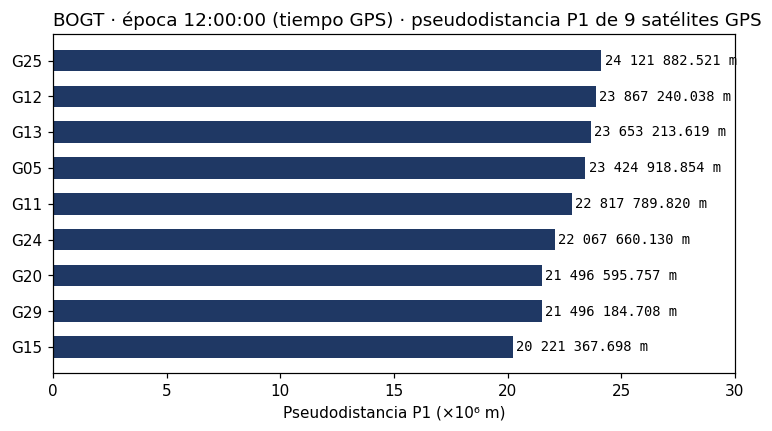

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ep.sv, ep.P1 / 1e6, color=AZUL, height=0.6)
for sv, valor in zip(ep.sv, ep.P1):
    ax.text(valor / 1e6 + 0.15, sv, f"{valor:,.3f} m".replace(",", " "), va="center", family="monospace", fontsize=9)
ax.set_xlim(0, 30)
ax.set_xlabel("Pseudodistancia P1 (×10⁶ m)")
ax.set_title(f"{ESTACION[:4]} · época {HORA} (tiempo GPS) · pseudodistancia P1 de {len(ep)} satélites GPS", loc="left");

## 3. Pseudodistancia de un satélite durante su pase

Siguiendo un solo satélite (G15) durante horas, la pseudodistancia baja, pasa por un mínimo y vuelve a subir: el satélite **sale por el horizonte, culmina y se oculta**. En el mínimo el satélite está cerca del cenit de la estación, así que ese mínimo se acerca a $a - R$, la distancia entre la estación y un satélite en su cenit: unos 20 200 km (sección 6). La columna `el` (elevación sobre el horizonte, en grados) confirma la lectura.

G15 visible de 08:55 a 15:09 (374 min)
pseudodistancia mínima 20 180 322 m a las 11:45:30; elevación máxima 72.5°


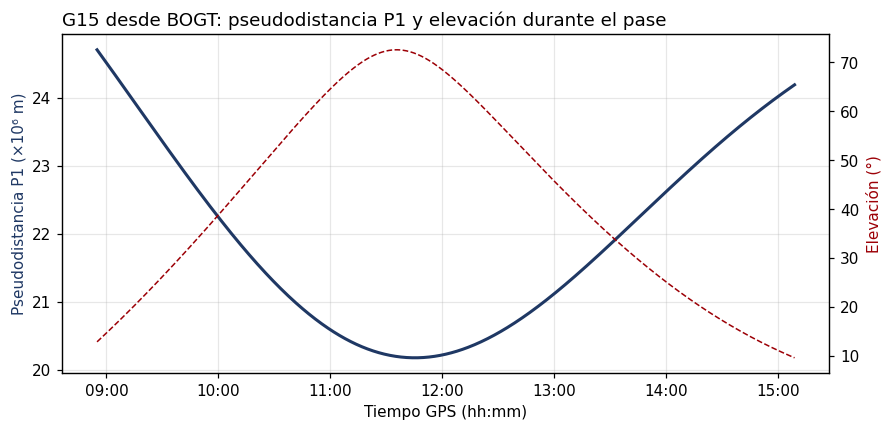

In [10]:
g15 = D[D.sv == SAT].set_index("t").sort_index()      # el satélite elegido (G15 en el ejemplo)

# un "pase" es el tramo continuo en que el satélite estuvo visible: se corta donde hay un hueco de más de 5 min
hueco = g15.index.to_series().diff() > pd.Timedelta("5min")
numero_de_pase = hueco.cumsum()
pase_de_las_12 = numero_de_pase[g15.index[g15.index.get_indexer([t0], method="nearest")[0]]]
pase = g15[numero_de_pase == pase_de_las_12]

duracion_min = (pase.index[-1] - pase.index[0]).total_seconds() / 60
print(f"{SAT} visible de {pase.index[0].strftime('%H:%M')} a {pase.index[-1].strftime('%H:%M')} ({duracion_min:.0f} min)")
print(f"pseudodistancia mínima {pase.P1.min():,.0f} m a las {pase.P1.idxmin().strftime('%H:%M:%S')}; elevación máxima {pase.el.max():.1f}°".replace(",", " "))

fig, ax1 = plt.subplots(figsize=(9, 4))
ax2 = ax1.twinx()                                   # segundo eje para la elevación
ax1.plot(pase.index, pase.P1 / 1e6, color=AZUL, lw=2)
ax2.plot(pase.index, pase.el, color=ROJO, lw=1, ls="--")
ax1.set_ylabel("Pseudodistancia P1 (×10⁶ m)", color=AZUL)
ax2.set_ylabel("Elevación (°)", color=ROJO)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax1.set_xlabel("Tiempo GPS (hh:mm)")
ax1.set_title(f"{SAT} desde {ESTACION[:4]}: pseudodistancia P1 y elevación durante el pase", loc="left")
ax1.grid(alpha=0.3);

## 4. Número de satélites observados por época

Los satélites entran y salen continuamente, pero nunca faltan. La línea de **cuatro** marca el mínimo con el que un receptor puede calcular su posición (tres coordenadas y su propio reloj; sección 12).

satélites GPS por época: mínimo 7, máximo 12, media 9.5


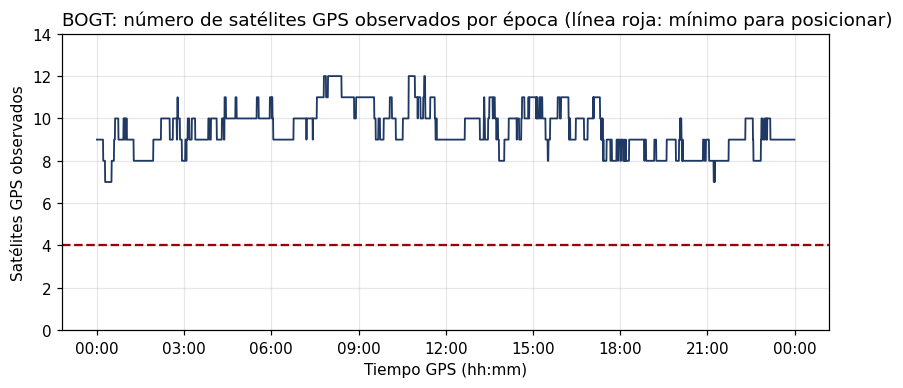

In [11]:
n_por_epoca = D.groupby("t").sv.count()             # cuántos satélites tienen medida en cada época
print(f"satélites GPS por época: mínimo {n_por_epoca.min()}, máximo {n_por_epoca.max()}, media {n_por_epoca.mean():.1f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(n_por_epoca.index, n_por_epoca.values, color=AZUL, lw=1.2)
ax.axhline(4, color=ROJO, ls="--")
ax.set_ylim(0, 14)
ax.set_ylabel("Satélites GPS observados")
ax.set_xlabel("Tiempo GPS (hh:mm)")
ax.set_title(f"{ESTACION[:4]}: número de satélites GPS observados por época (línea roja: mínimo para posicionar)", loc="left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.grid(alpha=0.3);

## 5. Pseudodistancia y medición de tiempo: sensibilidad al error de reloj

> El receptor no mide metros: mide **cuánto tarda la señal en llegar** y lo multiplica por $c = 299\,792\,458$ m/s (sección 0). Si los dos relojes marcaran el tiempo GPS exacto, $c\,(t_R - t^s)$ sería la distancia recorrida; como no lo hacen, es la pseudodistancia $P$, y **cada error de tiempo pasa a la distancia multiplicado por $c$**.

Esa multiplicación convierte errores de tiempo en errores de distancia: 1 ns son 30 cm; 1 µs, 300 m; 1 ms, 300 km. Medir 20 000 km con precisión de metros exige medir tiempos con precisión de **nanosegundos**. Por eso los satélites llevan relojes atómicos, y aun así cada uno tiene un desfase de cientos de microsegundos, que el propio satélite transmite para corregirlo ($\delta t^s$, sección 8). El receptor lleva un reloj de cuarzo, mucho menos estable, y su desfase hay que estimarlo ($\delta t_R$, sección 7).

El tiempo de viaje del satélite elegido, $\tau = P1/c$, ya se calculó en la sección 0. Es el tiempo **medido**: incluye el desfase de los dos relojes, no solo el viaje de la señal.


In [12]:
# cuánto error en la distancia produce cada error en el tiempo: Δd = c·Δt
for dt, nombre in [(1e-9, "1 ns"), (1e-6, "1 µs"), (1e-3, "1 ms")]:
    print(f"{nombre:>6} de error en el tiempo -> {C*dt:>12,.2f} m de error en la distancia".replace(",", " "))


  1 ns de error en el tiempo ->         0.30 m de error en la distancia
  1 µs de error en el tiempo ->       299.79 m de error en la distancia
  1 ms de error en el tiempo ->   299 792.46 m de error en la distancia


## 6. Posición del satélite a partir de las efemérides transmitidas

Cada satélite transmite sus **efemérides** (los seis elementos de su órbita más pequeñas correcciones) y con ellas se calcula dónde estaba en el instante de emisión. Esa posición ya está en la tabla (`xs`, `ys`, `zs`), en coordenadas geocéntricas (sección 1), en el mismo sistema que la posición de la estación.

### Distancias entre la estación y el satélite: un modelo de referencia

Para saber qué distancias esperar se usa un modelo geométrico simple, con dos magnitudes:

| símbolo | qué es | cómo se obtiene |
|---|---|---|
| $a$ | radio de la órbita, supuesta circular: distancia del satélite al centro de la Tierra | radio nominal de GPS, 26 560 km; los radios reales de cada satélite son $\sqrt{x_s^2 + y_s^2 + z_s^2}$ |
| $R$ | distancia de la estación al centro de la Tierra | $R = \sqrt{X^2 + Y^2 + Z^2}$, con las coordenadas del encabezado (`rx`) |

1. **Las coordenadas geocéntricas no dependen del elipsoide.** X, Y, Z son distancias cartesianas desde el centro de masas de la Tierra, y $R$ se calcula directamente con ellas. El elipsoide (WGS84) solo entra para expresar el mismo punto como latitud, longitud y altura. Lo que sí importa es que la estación y los satélites estén en el mismo marco de referencia: las efemérides GPS se dan en WGS84, que coincide con el marco terrestre internacional (ITRF) al nivel de centímetros, y la posición del encabezado está en ese marco.
2. **$R$ ya incluye la altura de la estación.** Descompuesto con el elipsoide, $R$ es aproximadamente el radio del elipsoide en la latitud $\varphi$ de la estación más su altura elipsoidal $h$:
$$R \approx r_{\text{elipsoide}}(\varphi) + h$$
El radio del elipsoide disminuye del ecuador (6 378,1 km) al polo (6 356,8 km), así que $R$ cambia de una estación a otra: no es un radio fijo. La celda siguiente lo comprueba.
3. **Satélite en el cenit: $d_{\min} = a - R$.** El satélite está en la prolongación de la línea que va del centro de la Tierra a la estación, y la distancia entre los dos es la diferencia de sus distancias al centro. Es la distancia mínima.
4. **Satélite en el horizonte: $d_{\max} = \sqrt{a^2 - R^2}$.** La línea de visión es horizontal, perpendicular al radio de la estación: el centro de la Tierra, la estación y el satélite forman un triángulo rectángulo con hipotenusa $a$ y un cateto $R$. Por Pitágoras, el otro cateto es la distancia. Es la distancia máxima.
5. **La altura de la órbita es otra magnitud.** La altura del satélite sobre la superficie media de la Tierra, $a - 6\,371$ km ≈ 20 200 km, es un dato de la órbita y no depende de la estación. Se parece a $a - R$ porque $R$ es cercano al radio medio, pero $a - R$ es la distancia **desde la estación**.

Supuestos del modelo:

| supuesto | realidad | efecto |
|---|---|---|
| órbita circular de radio $a$ | elipses casi circulares, con radios de unos 26 200 a 26 900 km | algunas distancias medidas caen algo fuera del rango |
| vertical geocéntrica (la línea al centro de la Tierra) | la vertical del elipsoide difiere menos de 0,2° | despreciable |
| la estación es el punto `rx` | `rx` es el marcador de la estación; la antena está más arriba, a la altura que da el encabezado (`ANTENNA: DELTA H/E/N`) | centímetros |
| se compara con la pseudodistancia `P1` | `P1` incluye $c\,\delta t_R$ (sección 7) | metros en una estación con el reloj ajustado al tiempo GPS; en una con el reloj desfasado, hasta cientos de kilómetros |


In [13]:
ep["radio_km"] = np.sqrt(ep["xs"]**2 + ep["ys"]**2 + ep["zs"]**2) / 1e3   # distancia del satélite al centro de la Tierra
print(ep[["sv", "radio_km"]].round(1).to_string(index=False))

R_t = np.linalg.norm(rx) / 1e3    # R: distancia de la estación al centro de la Tierra (km)
a = 26560.0                       # radio nominal de la órbita GPS (km)

# R descompuesto con el elipsoide WGS84: distancia al centro del punto del elipsoide bajo la estación, más la altura elipsoidal
lat, lon, h = xyz_a_geodesicas(*rx)
a_wgs, f_wgs = 6378137.0, 1 / 298.257223563
e2_wgs = f_wgs * (2 - f_wgs)
fi = np.radians(lat)
N = a_wgs / np.sqrt(1 - e2_wgs * np.sin(fi) ** 2)                          # radio de curvatura en el primer vertical
r_elip = np.hypot(N * np.cos(fi), N * (1 - e2_wgs) * np.sin(fi)) / 1e3    # radio del elipsoide en esa latitud (km)
print(f"\nR = |rx| = {R_t:,.3f} km  ≈  radio del elipsoide en {lat:.2f}° ({r_elip:,.3f} km) + h ({h/1e3:,.3f} km) = {r_elip + h/1e3:,.3f} km".replace(",", " "))
print(f"antena sobre el marcador (ANTENNA: DELTA H): {enc.get('antena_dh', np.nan):.4f} m")

print(f"\nradio de las órbitas en esta época: de {ep.radio_km.min():,.0f} a {ep.radio_km.max():,.0f} km".replace(",", " "))
print(f"órbita circular de {a:,.0f} km; estación a {R_t:,.1f} km del centro -> en el cenit: a - R = {a-R_t:,.0f} km   |   en el horizonte: sqrt(a² - R²) = {np.sqrt(a**2-R_t**2):,.0f} km".replace(",", " "))
print(f"pseudodistancia P1 mínima del pase de {SAT} (sección 3): {pase.P1.min()/1e3:,.0f} km; elevación máxima {pase.el.max():.1f}°".replace(",", " "))


 sv  radio_km
G15   26394.8
G29   26467.8
G20   26598.9
G24   26724.4
G11   26513.3
G05   26418.7
G13   26612.9
G12   26767.7
G25   26853.6

R = |rx| = 6 380.575 km  ≈  radio del elipsoide en 4.64° (6 377.998 km) + h (2.577 km) = 6 380.575 km
antena sobre el marcador (ANTENNA: DELTA H): 0.0610 m

radio de las órbitas en esta época: de 26 395 a 26 854 km
órbita circular de 26 560 km; estación a 6 380.6 km del centro -> en el cenit: a - R = 20 179 km   |   en el horizonte: sqrt(a² - R²) = 25 782 km
pseudodistancia P1 mínima del pase de G15 (sección 3): 20 180 km; elevación máxima 72.5°


## 7. Estimación y validación del desfase del reloj del receptor

> **Desfase del reloj del receptor**, $\delta t_R$ — diferencia entre la hora que marca el reloj del receptor y el tiempo GPS en el mismo instante: $\delta t_R = t_{\text{receptor}} - t_{\text{GPS}}$. Si es positivo, el reloj del receptor va adelantado, anota la llegada de cada señal más tarde de lo real, y todas las pseudodistancias salen $c\,\delta t_R$ más largas.

Este desfase afecta a todo lo que sigue, así que se mide antes de seguir. Se puede estimar sin resolver la posición, porque la estación tiene coordenadas conocidas. Se parte de la ecuación de la sección 0, con el paréntesis separado:
$$P1 = r + c\,\delta t_R - c\,\delta t^s + T + I + \varepsilon$$
La ecuación no se divide: se **reordena**, separando lo que se conoce de lo que no:

| término | ¿se conoce? | por qué |
|---|---|---|
| $P1$ | sí | lo midió el receptor |
| $r$ | sí | se calcula con las posiciones de la estación y del satélite |
| $c\,\delta t^s$ | sí | lo transmite el satélite (columna `dts`; sección 8) |
| $c\,\delta t_R$ | no | es lo que se quiere averiguar |
| $T$, $I$, $\varepsilon$ | no | atmósfera y ruido |

1. **Residuo de pseudodistancia.** Se resta $r$ a los dos lados y se suma $c\,\delta t^s$ a los dos lados. La ecuación sigue siendo cierta, y ahora todo lo conocido está a la izquierda:
$$P1 - r + c\,\delta t^s = c\,\delta t_R + T + I + \varepsilon$$
El lado izquierdo se puede calcular: da un número concreto, que se llama **residuo**. Con G15 a las 12:00, $20\,221\,367{,}698 - 20\,354\,736{,}807 + 133\,372{,}634 = 3{,}53$ m. El lado derecho dice de qué está hecho ese número: como los dos lados son iguales, $3{,}53 = c\,\delta t_R + T + I + \varepsilon$. Con un solo satélite no se puede saber cuánto es reloj y cuánto atmósfera.

Cada satélite da su propia ecuación. El subíndice $i$ indica el satélite: en una época con nueve satélites hay nueve medidas y nueve residuos ($i$ = G15, G29, …), y cada uno cumple
$$\text{residuo}_i = P1_i - r_i + c\,\delta t^s_i = c\,\delta t_R + T_i + I_i + \varepsilon_i$$
$c\,\delta t_R$ no lleva subíndice: es **el mismo para todos los satélites de la época**, porque hay un solo receptor con un solo reloj. Los demás términos cambian de un satélite a otro con la elevación. Esa diferencia es la que permite separarlo.
2. **Estimación en cada época.** El término común se estima con la mediana de los residuos de los satélites de la época $t$:
$$c\,\widehat{\delta t_R}(t) = \operatorname{mediana}_i\,\big[\text{residuo}_i(t)\big]$$
Se usa la mediana y no la media por dos razones: la atmósfera siempre suma, y los satélites bajos arrastrarían la media hacia arriba; y una medida errónea, que aparece en datos reales, no mueve la mediana. La mediana incluye la atmósfera de un satélite típico (unos metros), así que el método distingue el desfase al nivel de metros, es decir, de decenas de nanosegundos.
3. **Valor que se resta desde aquí.** Si el desfase no salta, se resta un solo valor para todo el día: la mediana de las estimaciones de todas las épocas. Si salta, se resta el de cada época. La mediana de cada época cambia unos metros cuando entra o sale un satélite, y un valor único evita trasladar esos cambios a las secciones siguientes.

Tres comprobaciones:

| comprobación | qué se calcula | qué indica |
|---|---|---|
| 1. Valor | la media de $c\,\widehat{\delta t_R}$, en tiempo y en metros | cuánto se aparta el reloj del receptor del tiempo GPS |
| 2. Consistencia a lo largo del día | el rango, la deriva (pendiente de una recta ajustada) y los saltos entre épocas | constante: un reloj estable desplazado del tiempo GPS; deriva lineal: un oscilador que nadie corrige; saltos de casi 1 ms (unos 300 km): un receptor que corrige su reloj a saltos de un milisegundo |
| 3. Coincidencia entre satélites | el rango intercuartílico de los residuos de cada época | metros: el término común es del reloj; kilómetros: el problema está en la posición de la estación o en las órbitas, porque esos errores cambian con la dirección de cada satélite |


In [14]:
# cada medida menos la distancia geométrica, con el reloj del satélite corregido (sección 8), en todas las épocas y satélites del día
D["r"] = np.sqrt((rx[0] - D["xs"])**2 + (rx[1] - D["ys"])**2 + (rx[2] - D["zs"])**2)
D["resid"] = D.P1 - D.r + C * D.dts                  # = c·δt_R + T + I + ε

por_epoca = D.groupby("t").resid
reloj = por_epoca.median()                           # c·δt_R estimado en cada época (m)
dispersion = por_epoca.quantile(0.75) - por_epoca.quantile(0.25)   # cuánto difieren los satélites de una época (m)
salto = reloj.diff().abs()                           # cambio de una época a la siguiente (m)
horas = (reloj.index - reloj.index[0]).total_seconds() / 3600
deriva = np.polyfit(horas, reloj.values, 1)[0]       # pendiente de la recta ajustada (m por hora)

dtR = reloj.mean() / C                               # desfase medio (s)
en_tiempo = f"{dtR*1e3:.4f} ms" if abs(dtR) >= 1e-5 else f"{dtR*1e9:.0f} ns"   # en ms si es grande, en ns si es pequeño
print(f"1. desfase medio: δt_R = {en_tiempo}  ->  c·δt_R = {reloj.mean():,.1f} m".replace(",", " "))
print(f"2. en el día: de {reloj.min():,.1f} a {reloj.max():,.1f} m (desviación estándar {reloj.std():.1f} m)".replace(",", " "))
print(f"   deriva {deriva*24/C*1e9:+.0f} ns/día ({deriva*24:+.1f} m/día) | saltos de más de 100 m entre épocas: {(salto > 100).sum()}")
print(f"3. diferencia entre satélites de una época (rango intercuartílico): mediana {dispersion.median():.1f} m, percentil 95 {dispersion.quantile(0.95):.1f} m")

# el valor que se resta desde aquí: si el reloj no salta, uno solo para todo el día (la mediana);
# si salta, el de cada época. La mediana de cada época cambia unos metros cuando entra o sale un satélite.
estable = (salto > 100).sum() == 0
reloj_usado = pd.Series(reloj.median(), index=reloj.index) if estable else reloj
print(f"se resta: {'un valor para todo el día, ' + format(reloj.median(), ',.1f').replace(',', ' ') + ' m' if estable else 'el valor de cada época'}")


1. desfase medio: δt_R = 25 ns  ->  c·δt_R = 7.5 m
2. en el día: de 1.0 a 15.3 m (desviación estándar 2.8 m)
   deriva +16 ns/día (+4.8 m/día) | saltos de más de 100 m entre épocas: 0
3. diferencia entre satélites de una época (rango intercuartílico): mediana 4.4 m, percentil 95 9.2 m
se resta: un valor para todo el día, 7.6 m


mediana del residuo sin el reloj del receptor, por intervalo de elevación (m):
el
(0, 10]     14.3
(10, 20]     5.1
(20, 30]     1.4
(30, 50]    -1.4
(50, 90]    -3.8


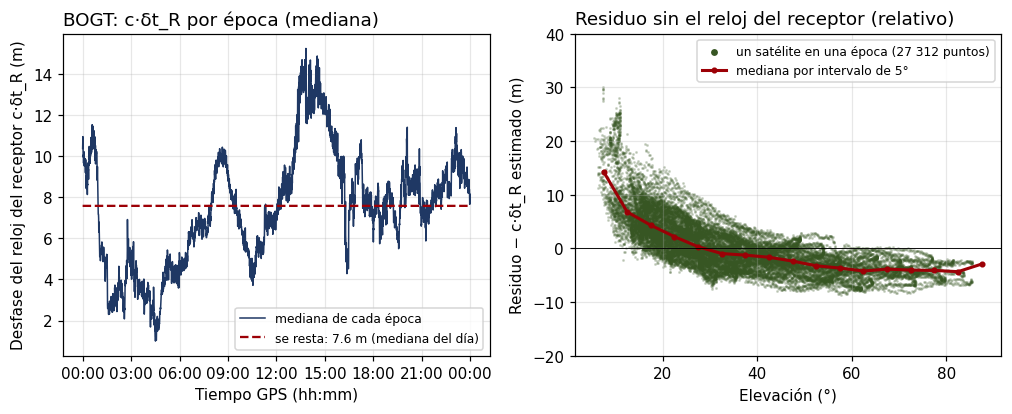

In [15]:
D["resid_sin_reloj"] = D.resid - D.t.map(reloj_usado)   # residuo sin el reloj del receptor: T + I + ε (relativo al valor que se resta)
print("mediana del residuo sin el reloj del receptor, por intervalo de elevación (m):")
print(D.groupby(pd.cut(D.el, [0, 10, 20, 30, 50, 90])).resid_sin_reloj.median().round(1).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(reloj.index, reloj.values, color=AZUL, lw=1, label="mediana de cada época")
ax1.plot(reloj_usado.index, reloj_usado.values, color=ROJO, lw=1.5, ls="--",       # el valor que se resta desde la sección 8
         label=f"se resta: {reloj.median():,.1f} m (mediana del día)".replace(",", " ") if estable else "se resta: el valor de cada época")
ax1.legend(loc="best", fontsize=8)
ax1.ticklabel_format(axis="y", useOffset=False, style="plain")     # que el eje muestre el valor completo, no una diferencia
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax1.set_xlabel("Tiempo GPS (hh:mm)")
ax1.set_ylabel("Desfase del reloj del receptor c·δt_R (m)")
ax1.set_title(f"{ESTACION[:4]}: c·δt_R por época (mediana)", loc="left")
ax1.grid(alpha=0.3)
ax2.scatter(D.el, D.resid_sin_reloj, s=1, alpha=0.2, color=VERDE, label=f"un satélite en una época ({len(D):,} puntos)".replace(",", " "))
tramos = pd.cut(D.el, np.arange(0, 95, 5))                                  # intervalos de 5° de elevación
por_tramo = D.groupby(tramos).resid_sin_reloj.median()
ax2.plot([t.mid for t in por_tramo.index], por_tramo.values, color=ROJO, lw=2, marker="o", ms=3, label="mediana por intervalo de 5°")
ax2.axhline(0, color="k", lw=0.6)
ax2.set_ylim(-20, 40)
ax2.set_xlabel("Elevación (°)")
ax2.set_ylabel("Residuo − c·δt_R estimado (m)")
ax2.set_title("Residuo sin el reloj del receptor (relativo)", loc="left")
leyenda = ax2.legend(loc="upper right", fontsize=8)
leyenda.legend_handles[0].set_sizes([12])           # que el punto de la leyenda se vea
leyenda.legend_handles[0].set_alpha(1)
ax2.grid(alpha=0.3);


En BOGT el desfase medio es de unos **25 ns (7,5 m)** y durante el día se mueve entre 1 y 15 m, sin un solo salto; la deriva que da la recta (unos +16 ns/día) es menor que esa oscilación, así que no es significativa. Esas cifras están en el límite de lo que el método distingue: la mediana arrastra los metros de atmósfera del satélite típico, que cambian con la hora, y con una sola frecuencia no se pueden separar de pequeñas variaciones del propio reloj, de decenas de nanosegundos. La conclusión es que el reloj de BOGT se mantiene pegado al tiempo GPS a ese nivel (el receptor, probablemente, lo ajusta de forma continua). La diferencia entre satélites de una época (mediana 4,4 m) confirma que la posición de la estación y las órbitas están bien.

A la derecha está lo que queda en cada satélite después de restar los 7,6 m de la línea roja (la mediana del día, que es lo que se resta; la media es 7,5 m): cada punto es un satélite en una época, y las estelas son los pases de cada satélite. Si lo restado era de verdad el reloj, lo que queda tiene que ser atmósfera, y la atmósfera crece cuando el satélite baja, porque la señal la atraviesa en un trayecto más largo. Es lo que se ve: la mediana (línea roja) pasa de unos +14 m cerca del horizonte a cero hacia los 30° y a unos −4 m con el satélite alto. Los valores negativos no significan que la atmósfera adelante la señal: los 7,6 m restados ya incluían la atmósfera de un satélite típico, así que los satélites altos, que atraviesan menos atmósfera que ese satélite típico, quedan por debajo de cero.

Con otra estación el resultado puede ser muy distinto. CRO1 (Saint Croix, Islas Vírgenes de EE. UU.) el 12 de enero de 2026 da un desfase de **4,27 ms**, es decir **1 279 km**, constante durante todo el día. Desde aquí el cuaderno resta el reloj del receptor (`reloj_usado`): como el desfase es estable, un solo valor para todo el día, su mediana. Con BOGT eso cambia unos metros; con una estación como CRO1 es indispensable para ver la atmósfera. Si el desfase saltara, se restaría el valor de cada época.


## 8. Pseudodistancia frente a distancia geométrica: corrección del reloj del satélite

> **Distancia geométrica** $r$ — la distancia real entre el satélite en el instante de emisión, $(x^s, y^s, z^s)$, y la estación, $(X, Y, Z)$:
> $$r = \sqrt{(X - x^s)^2 + (Y - y^s)^2 + (Z - z^s)^2}$$

Con la posición de la estación (la del encabezado) se calcula $r$ y se compara con la medida, ya sin el reloj del receptor (sección 7). Se parte de la ecuación de la sección 0, con todos sus términos:
$$P1 = r + c\,\delta t_R - c\,\delta t^s + T + I + \varepsilon$$
Después de la sección 7 se conocen $P1$, $r$ y $c\,\delta t_R$. Se restan $r$ y $c\,\delta t_R$ a los dos lados, y quedan a la izquierda; a la derecha siguen el reloj del satélite, la atmósfera y el ruido:
$$P1 - r - c\,\delta t_R = -c\,\delta t^s + T + I + \varepsilon$$
El lado derecho está dominado por el reloj del satélite, así que **no coinciden**: difieren en decenas o cientos de kilómetros (hasta unos 180 km en esta época), un valor distinto para cada satélite. Cada satélite marca la hora de emisión con un adelanto o atraso propio de cientos de microsegundos (300 km por milisegundo). El satélite conoce su desfase —el segmento de control lo mide y lo sube al mensaje— y lo transmite: es la columna `dts`, calculada con los coeficientes del mensaje (sección 0) y descontando el retardo de grupo $T_{GD}$ (definido en la sección 0), porque se usa el código de L1 solo. Al sumar $c\,\delta t^s$ a los dos lados, el reloj del satélite también pasa a la izquierda, y a la derecha quedan solo la atmósfera y el ruido, unos metros:
$$P1 - r + c\,\delta t^s - c\,\delta t_R = T + I + \varepsilon$$
mayores para los satélites bajos: la atmósfera (sección 9). En la figura, cada barra es un satélite de la época, y su altura es el lado izquierdo de una de las dos ecuaciones, calculado con los datos. A la izquierda, $P1 - r - c\,\delta t_R$, en kilómetros: por la primera ecuación vale $-c\,\delta t^s$ más unos metros, así que las barras son el reflejo del reloj de cada satélite, con el signo contrario. A la derecha, el mismo cálculo después de sumar $c\,\delta t^s$: por la segunda ecuación vale $T + I + \varepsilon$, unos metros, y crece cuando el satélite baja. Los valores son relativos, por la misma razón que en la sección 7: el $c\,\delta t_R$ restado incluye la atmósfera de un satélite típico, así que los satélites altos quedan por debajo de cero.


In [16]:
# distancia geométrica: del satélite (en el instante de emisión) a la posición de la estación
ep["r"] = np.sqrt((rx[0] - ep["xs"])**2 + (rx[1] - ep["ys"])**2 + (rx[2] - ep["zs"])**2)

ep["c_dtR"] = reloj_usado[t0]                # reloj del receptor (sección 7)
ep["P_menos_r"] = ep.P1 - ep.r - ep.c_dtR    # medida − geométrica − reloj del receptor: debería ser ~0 si los satélites tuvieran relojes perfectos
ep["c_dts"] = C * ep.dts                     # desfase del reloj del satélite, pasado a metros
ep["resid_sin_reloj"] = ep.P_menos_r + ep.c_dts   # residuo sin los dos relojes: T + I + ε (relativo), como en la sección 7

ep[["sv", "el", "P1", "r", "c_dtR", "P_menos_r", "c_dts", "resid_sin_reloj"]].round(3)


,sv,el,P1,r,c_dtR,P_menos_r,c_dts,resid_sin_reloj
0,G15,68.513,2.022137e+07,2.035474e+07,7.588,-133376.697,133372.634,-4.063
1,G29,47.305,2.149618e+07,2.142342e+07,7.588,72759.605,-72763.214,-3.609
2,G20,46.896,2.149660e+07,2.158236e+07,7.588,-85767.197,85762.858,-4.340
3,G24,40.558,2.206766e+07,2.213019e+07,7.588,-62541.219,62539.257,-1.961
4,G11,29.830,2.281779e+07,2.275506e+07,7.588,62718.293,-62718.618,-0.325
5,G05,22.068,2.342492e+07,2.335393e+07,7.588,70985.145,-70984.934,0.211
6,G13,19.560,2.365321e+07,2.378586e+07,7.588,-132649.945,132652.265,2.320
7,G12,22.278,2.386724e+07,2.368675e+07,7.588,180487.273,-180485.335,1.937
8,G25,17.461,2.412188e+07,2.423832e+07,7.588,-116442.844,116446.638,3.794


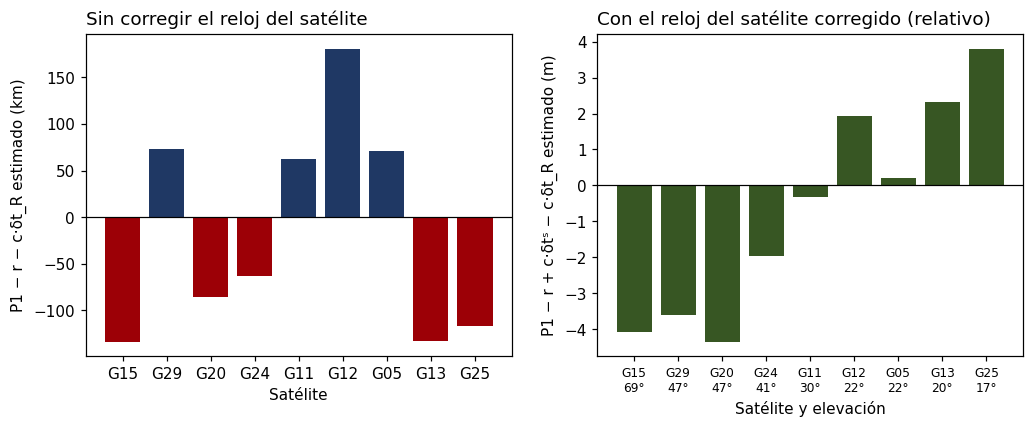

In [17]:
e2 = ep.sort_values("el", ascending=False)    # de más alto a más bajo sobre el horizonte
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))

colores = [ROJO if v < 0 else AZUL for v in e2.P_menos_r]
axs[0].bar(e2.sv, e2.P_menos_r / 1e3, color=colores)
axs[0].axhline(0, color="k", lw=0.8)
axs[0].set_xlabel("Satélite")
axs[0].set_ylabel("P1 − r − c·δt_R estimado (km)")
axs[0].set_title("Sin corregir el reloj del satélite", loc="left")
axs[1].bar(e2.sv, e2.resid_sin_reloj, color=VERDE)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xlabel("Satélite y elevación")
axs[1].set_ylabel("P1 − r + c·δtˢ − c·δt_R estimado (m)")
axs[1].set_title("Con el reloj del satélite corregido (relativo)", loc="left")
axs[1].set_xticks(range(len(e2)))
axs[1].set_xticklabels([f"{s}\n{e:.0f}°" for s, e in zip(e2.sv, e2.el)], fontsize=8);


## 9. Residuo de pseudodistancia frente a la elevación: retardo atmosférico

Tras corregir los dos relojes, el residuo es la atmósfera más el ruido. El del receptor se corrige restando el valor estimado en la sección 7 (`reloj_usado`: en BOGT, la mediana del día, 7,6 m), y el del satélite sumando $c\,\delta t^s$, el desfase que él mismo transmite (columna `dts`, sección 8):
$$P1 - r + c\,\delta t^s - c\,\delta t_R = T + I + \varepsilon$$
Los dos retardos crecen cuando el satélite baja, porque la señal recorre más atmósfera. Para la troposfera, en primera aproximación y con elevaciones mayores de unos 15°:
$$T(E) \approx \frac{T_{\text{cenit}}}{\sin E}$$
donde $E$ es la elevación y $T_{\text{cenit}}$ el retardo con el satélite en el cenit: unos 2,3 m a nivel del mar, y algo menos en una estación alta como BOGT, que tiene encima menos atmósfera. La figura sigue a G15 durante todo su pase: cada punto es el lado izquierdo de la ecuación, calculado en una época, y la línea roja es la mediana de todos los satélites del día por intervalo de elevación (la de la sección 7), como referencia.


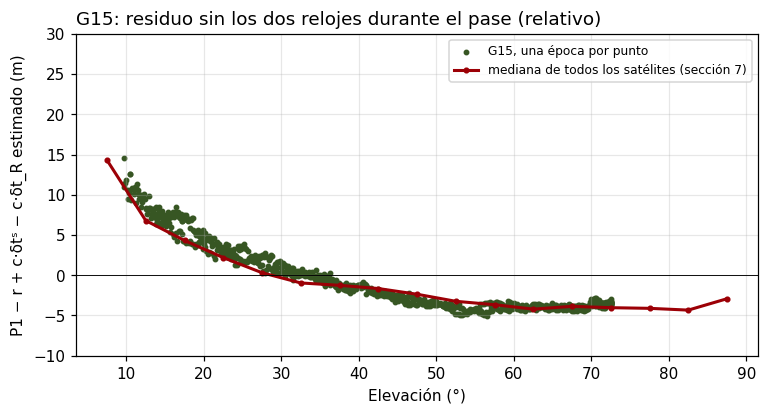

In [18]:
pase = pase.copy()
pase["r"] = np.sqrt((rx[0] - pase["xs"])**2 + (rx[1] - pase["ys"])**2 + (rx[2] - pase["zs"])**2)
pase["resid"] = pase.P1 - pase.r + C * pase.dts - reloj_usado.reindex(pase.index).values   # medida − geométrica + c·δtˢ − c·δt_R (sección 7)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(pase.el, pase.resid, s=8, color=VERDE, label=f"{SAT}, una época por punto")
ax.plot([t.mid for t in por_tramo.index], por_tramo.values, color=ROJO, lw=2, marker="o", ms=3,
        label="mediana de todos los satélites (sección 7)")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("Elevación (°)")
ax.set_ylabel("P1 − r + c·δtˢ − c·δt_R estimado (m)")
ax.set_ylim(-10, 30)
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)
ax.set_title(f"{SAT}: residuo sin los dos relojes durante el pase (relativo)", loc="left");


G15 sigue la forma de la troposfera: unos +8 m por debajo de 15° de elevación (hasta +14,6 m a 10°), unos +2,5 m entre 20° y 30°, y unos −4 m por encima de 45°, en el mismo rango que la mediana de todos los satélites. Los valores son **relativos**, como en las secciones 7 y 8: el valor del reloj del receptor que se resta incluye la atmósfera de un satélite típico, así que los satélites altos quedan algo por debajo de cero.

Los puntos no forman una sola curva: a la misma elevación, la subida y la bajada de G15 difieren entre uno y dos metros por debajo de 30° (entre 15° y 25°, unos +3,6 m al subir y +5,1 m al bajar). La subida ocurre de madrugada y la bajada a media mañana, con más ionosfera, que es lo que estudia la sección 10.


## 10. Diferencia entre las frecuencias L1 y L2: retardo ionosférico

El mismo satélite se mide a la vez en L1 (`P1`) y L2 (`P2`). La ecuación de la sección 0 vale para cada frecuencia, y casi todos sus términos son iguales en las dos: la distancia $r$, los dos relojes y la troposfera, que no depende de la frecuencia. Cambian dos:

1. **La ionosfera.** Los electrones libres de la ionosfera retrasan el código en proporción inversa al cuadrado de la frecuencia:
$$I = \frac{40{,}3\,\text{TEC}}{f^2}$$
donde TEC (*Total Electron Content*, contenido total de electrones) es el número de electrones libres en una columna de 1 m² de sección a lo largo del trayecto de la señal. Las dos señales recorren el mismo trayecto, con el mismo TEC, así que el retardo en L2 es el de L1 multiplicado por el cociente de los cuadrados de las frecuencias:
$$I_2 = \gamma\, I_1, \qquad \gamma = \left(\frac{f_1}{f_2}\right)^2 = \left(\frac{1575{,}42\ \text{MHz}}{1227{,}60\ \text{MHz}}\right)^2 = 1{,}647$$
2. **Los retardos instrumentales.** Cada señal pasa por circuitos distintos en el satélite y en el receptor, así que cada una tiene su propio retardo de código: $b_1$ en L1 y $b_2$ en L2. En la ecuación de la sección 0 estaban dentro de $\varepsilon$.

Con esos dos cambios, las ecuaciones de las dos frecuencias son:
$$P1 = r + c\,(\delta t_R - \delta t^s) + T + I_1 + b_1 + \varepsilon_1$$
$$P2 = r + c\,(\delta t_R - \delta t^s) + T + \gamma\, I_1 + b_2 + \varepsilon_2$$
Al restarlas se cancela todo lo común, $r$, los dos relojes y la troposfera, y queda:
$$P2 - P1 = (\gamma - 1)\, I_1 + b + (\varepsilon_2 - \varepsilon_1), \qquad b = b_2 - b_1$$

| término | qué es | orden de magnitud |
|---|---|---|
| $\gamma - 1$ | cuánto más retrasa la ionosfera a L2 que a L1: un 64,7 % más | constante, 0,647 |
| $I_1$ | retardo ionosférico en L1 | de 1 a decenas de metros; mayor de día y con el satélite bajo |
| $b$ | **sesgo diferencial de código** (DCB, *Differential Code Bias*): la diferencia entre los retardos de código de L2 y L1, con una parte del satélite, que es la que fija su $T_{GD}$ (sección 0), y otra del receptor | unos metros, positivo o negativo; casi constante en un día |
| $\varepsilon_2 - \varepsilon_1$ | ruido de la medida de código en las dos frecuencias | decímetros a un metro; mayor en L2, que se sigue sin descifrar el código |

Despejando, $I_1 = \big[(P2 - P1) - b\big] / (\gamma - 1)$: si se conoce $b$, la diferencia entre frecuencias **mide** la ionosfera. Así trabajan los receptores de doble frecuencia, y por eso el IGS publica los valores de $b$ de cada satélite y de cada receptor.

La figura muestra $P2 - P1$ de G15 durante su pase, que va de las 03:54 a las 10:08 hora de Colombia, con el color según la elevación.


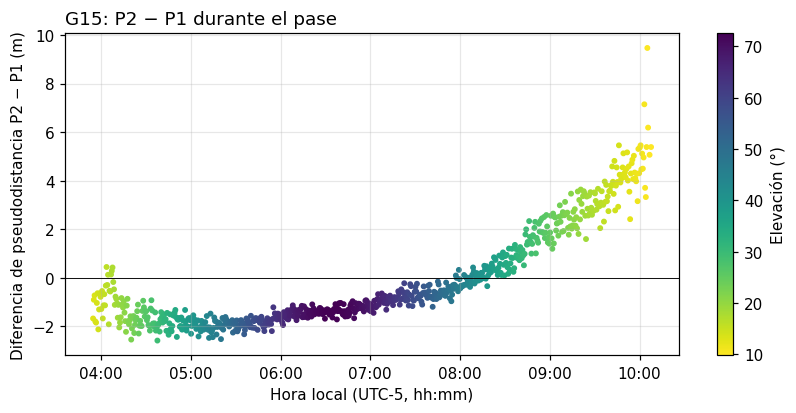

In [19]:
# tiempo GPS -> UTC (restar los 18 s intercalares) -> hora local (UTC + HUSO; Colombia: −5)
hora_local = pase.index + pd.Timedelta(hours=HUSO) - pd.Timedelta(seconds=18)

fig, ax = plt.subplots(figsize=(9, 3.8))
sc = ax.scatter(hora_local, pase.P2 - pase.P1, s=8, c=pase.el, cmap="viridis_r")
fig.colorbar(sc, ax=ax, label="Elevación (°)")
ax.axhline(0, color="k", lw=0.6)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel(f"Hora local (UTC{HUSO:+d}, hh:mm)")
ax.set_ylabel("Diferencia de pseudodistancia P2 − P1 (m)")
ax.set_title(f"{SAT}: P2 − P1 durante el pase", loc="left")
ax.grid(alpha=0.3);

**Cómo leer la figura.** El eje horizontal es la hora local; el vertical, $P2 - P1$ en metros; el color, la elevación del satélite (amarillo, bajo; morado, alto). Según la ecuación anterior, cada punto vale $(\gamma - 1)\,I_1 + b$ más el ruido. Como $b$ es casi constante durante el día, lo que mueve los puntos hacia arriba o hacia abajo es la ionosfera.

1. **De madrugada (de las 03:54 a las 07:00).** $P2 - P1$ se mantiene casi constante, entre −1 y −1,9 m. Al salir, a las 03:54, el satélite está bajo (amarillo, unos 10°) y su señal atraviesa mucha ionosfera, y aun así la diferencia apenas sube: de noche la ionosfera tiene pocos electrones. Lo que se ve es sobre todo $b$, unos −1,7 m.
2. **Después del amanecer (de las 07:00 a las 10:08).** $P2 - P1$ crece hasta unos +5,2 m al final del pase. Se suman dos efectos: el sol ioniza la atmósfera, y el satélite, que culminó a las 06:35, va bajando, así que su señal atraviesa cada vez más ionosfera.
3. **La misma elevación a dos horas distintas.** Los puntos amarillos del comienzo y del final del pase tienen la misma elevación, unos 10°, y el mismo trayecto por la atmósfera. Al comienzo, de noche, $P2 - P1$ vale alrededor de −1 m; al final, con el sol alto, unos +5 m. Esa diferencia la producen solo los electrones que liberó el sol: es la prueba de que se está viendo la ionosfera y no la geometría.
4. **La dispersión.** Los puntos amarillos están más dispersos que los morados: con el satélite bajo la señal llega más débil y el ruido de la medida, $\varepsilon_2 - \varepsilon_1$, es mayor, sobre todo en L2, que se sigue sin descifrar el código.

**Cuánto vale la ionosfera.** Despejando, $I_1 = \big[(P2 - P1) - b\big] / (\gamma - 1)$. Si $b$ es aproximadamente el valor de la madrugada, unos −1,7 m, al final del pase $(P2 - P1) - b \approx 5{,}2 - (-1{,}7) = 6{,}9$ m, y el retardo ionosférico en L1 es de unos $6{,}9 / 0{,}647 \approx 11$ m (en L2, $\gamma\,I_1 \approx 18$ m). Es un valor mínimo: se supuso que de madrugada la ionosfera era nula, y algo había.

**Relación con la sección 9.** Con el satélite bajo, el residuo de la sección 9 vale entre +8 y +14 m. Es del mismo orden que esta ionosfera, así que buena parte de lo que allí aparece como atmósfera, sobre todo en la bajada del satélite, es ionosfera, y no solo troposfera.


## 11. Ecuación de observación de la pseudodistancia

> **Pseudodistancia** $P$ (*pseudorange*; en la literatura suele escribirse $\rho$) — la distancia que mide el código: la geométrica más el efecto de los dos relojes, de la atmósfera y del ruido (sección 0):
> $$P = r + c\,(\delta t_R - \delta t^s) + T + I + \varepsilon$$

La tabla de la sección 0 define cada término y su orden de magnitud. Las secciones anteriores los separaron uno a uno: $r$ con las posiciones (secciones 7 y 8), $c\,\delta t_R$ con la mediana de los residuos (sección 7), $c\,\delta t^s$ con el mensaje del satélite (sección 8), $T$ con la forma del residuo frente a la elevación (sección 9) e $I$ con la diferencia entre frecuencias (sección 10).

Con los números de G15 a las 12:00:00, todo cuadra: el reloj del satélite explica 133 km, el del receptor unos 8 m, y lo que queda son unos metros, casi todos de atmósfera (relativos: G15 está alto, a 68°, y queda por debajo de cero).


In [20]:
g = ep[ep.sv == SAT].iloc[0]
c_dtR = reloj_usado[t0]                 # el reloj del receptor que se resta (sección 7)
print(f"P1       = {g.P1:,.3f} m".replace(",", " "))
print(f"r        = {g.r:,.3f} m".replace(",", " "))
print(f"c·δtˢ    = {C*g.dts:,.1f} m   (δtˢ = {g.dts*1e6:.3f} µs)".replace(",", " "))
print(f"P1 − r + c·δtˢ = {g.P1 - g.r + C*g.dts:,.2f} m  = c·δt_R + T + I + ε".replace(",", " "))
print(f"c·δt_R   = {c_dtR:,.1f} m   (sección 7)".replace(",", " "))
print(f"P1 − r + c·δtˢ − c·δt_R = {g.P1 - g.r + C*g.dts - c_dtR:,.2f} m  = T + I + ε (relativo)".replace(",", " "))


P1       = 20 221 367.698 m
r        = 20 354 736.807 m
c·δtˢ    = 133 372.6 m   (δtˢ = 444.883 µs)
P1 − r + c·δtˢ = 3.53 m  = c·δt_R + T + I + ε
c·δt_R   = 7.6 m   (sección 7)
P1 − r + c·δtˢ − c·δt_R = -4.06 m  = T + I + ε (relativo)


## 12. Número mínimo de satélites: cuatro incógnitas

Para cada satélite $i$ de una época, la ecuación de la sección 0 con los términos conocidos a la izquierda:
$$P_i + c\,\delta t^s_i - T_i - I_i = \sqrt{(X - x^s_i)^2 + (Y - y^s_i)^2 + (Z - z^s_i)^2} + c\,\delta t_R + \varepsilon_i$$
Lo conocido: $P_i$ (medido), $x^s_i, y^s_i, z^s_i, \delta t^s_i$ (del mensaje), $T_i$ (de un modelo de la troposfera) e $I_i$ (medido con dos frecuencias o, en un receptor de una sola frecuencia, de un modelo del mensaje). Lo desconocido, y común a todas las ecuaciones: $X, Y, Z$ y $\delta t_R$. En la sección 7 la posición de la estación era conocida y la única incógnita era $\delta t_R$; un receptor que no conoce su posición tiene las cuatro. **Cuatro incógnitas** → hacen falta al menos cuatro satélites. BOGT tuvo nueve a las 12:00 y nunca menos de siete en el día. Resolver ese sistema es el tema del cuaderno `gnss_estimacion_posicion.ipynb`.


## Referencias

- IS-GPS-200, *Navstar GPS Space Segment/Navigation User Segment Interfaces* (gps.gov/technical/icwg): señal, mensaje de navegación, cálculo de la posición y el reloj del satélite.
- ESA Navipedia (gssc.esa.int/navipedia): GPS Space Segment, GPS Signal Plan, GPS Navigation Message.
- Leick, A., Rapoport, L. y Tatarnikov, D. (2015). *GPS Satellite Surveying*, 4.ª ed. Wiley.
- Blewitt, G. (1997). *Basics of the GPS Technique: Observation Equations, Software Developments, and Data Processing*.
- IGS, International GNSS Service (igs.org); datos de BOGT del centro de datos IGS en BKG: https://igs.bkg.bund.de/root_ftp/IGS/obs/2026/258/ . RINEX 3.04 (IGS/RTCM RINEX Working Group, 2018).
- Paquete `hatanaka` (descompresión de los archivos `.crx`): https://pypi.org/project/hatanaka/